# 00 — Data Setup and Sanity Checks

In [1]:
import os
import sys
import json
import subprocess
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from rich.table import Table

In [ ]:
# Bootstrap: same cell works on a local kernel and on a Colab kernel (VS Code Colab extension).
# On Colab the code runs on Google's VM, which only sees what is *pushed* to GitHub:
# commit + push your changes, set BRANCH, then run this cell.
import os
import subprocess
import sys
from pathlib import Path

BRANCH = "feat/convNext-baseline"
REPO_URL = "https://github.com/LeafLab-AI/plant-disease-tl.git"
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_ROOT = Path("/content/plant-disease-tl")
    git = ["git", "-C", str(PROJECT_ROOT)]
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}  # fail fast instead of hanging on a prompt
    if not (PROJECT_ROOT / ".git").exists():
        cmds = [["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(PROJECT_ROOT)]]
    else:
        cmds = [[*git, "fetch", "-q", "origin", BRANCH], [*git, "checkout", "-q", "-B", BRANCH, "FETCH_HEAD"]]
    for cmd in cmds:
        if subprocess.run(cmd, env=env).returncode != 0:
            raise RuntimeError(f"git failed for branch '{BRANCH}': is it pushed, and is the repo public?")
else:
    PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if IN_COLAB:
    from src.colab import setup_runtime
    setup_runtime()
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

In [ ]:
CONFIG_DIR = PROJECT_ROOT / "configs"
CONFIG_FILE = CONFIG_DIR / "base.yaml"
DATA = PROJECT_ROOT / "data"

with open(CONFIG_FILE, "r") as file:
    CONFIGURATION = yaml.safe_load(file)

## 1. Download (skipped if already present)

In [4]:
provenance_file = DATA / 'provenance.json'
if provenance_file.exists():
    print('data/ already downloaded, skipping.')
else:
    download_script = PROJECT_ROOT / 'scripts' / 'download_data.py'
    subprocess.run([sys.executable, str(download_script), '--out', str(DATA)], check=True)

data/ already downloaded, skipping.


## 2. Download provenance

In [5]:
with open(DATA / 'provenance.json', 'r') as f:
    prov = json.load(f)

## 3. Build manifest, deduplicate, stratify-split

In [ ]:
from src.datasets import DataManager
dm = DataManager(CONFIGURATION)
dm.prepare_data()
df = dm.df
class_to_idx = dm.class_to_idx

In [10]:
# Cleaning now lives in DataManager._clean (configs/base.yaml -> data.clean), so every
# model trains on exactly this table: conflicting-label groups dropped, one image per group.
report = json.loads(dm.report_path.read_text())
print(json.dumps(report["cleaning"], indent=2))
print("split counts:", report["split_counts"])
assert df.groupby('group')['label'].nunique().max() == 1 and not df['group'].duplicated().any()
df

,path,label,width,height,phash,group,split
0,/home/ambitiousflow/projects/plant-disease-tl/...,Corn___Common_Rust,256,256,c1c93fca303e2736,0,val
1,/home/ambitiousflow/projects/plant-disease-tl/...,Corn___Common_Rust,256,256,c0e0249769dceb9d,1,train
2,/home/ambitiousflow/projects/plant-disease-tl/...,Corn___Common_Rust,256,256,90c05ec25a4778ff,2,test
3,/home/ambitiousflow/projects/plant-disease-tl/...,Corn___Common_Rust,256,256,90950f72ad83bec5,3,train
4,/home/ambitiousflow/projects/plant-disease-tl/...,Corn___Common_Rust,256,256,85350f9778d6e1e0,4,train
...,...,...,...,...,...,...,...
40218,/home/ambitiousflow/projects/plant-disease-tl/...,Tomato___Yellow_Leaf_Curl_Virus,640,640,d362046b88db13fd,40218,test
40219,/home/ambitiousflow/projects/plant-disease-tl/...,Tomato___Yellow_Leaf_Curl_Virus,640,640,c5dd519c1c061f37,40219,train
40220,/home/ambitiousflow/projects/plant-disease-tl/...,Tomato___Yellow_Leaf_Curl_Virus,640,640,d18805cc4d575e6f,40220,val
40221,/home/ambitiousflow/projects/plant-disease-tl/...,Tomato___Yellow_Leaf_Curl_Virus,640,640,c46905f60ded1bca,40221,train


## 4. Class distribution

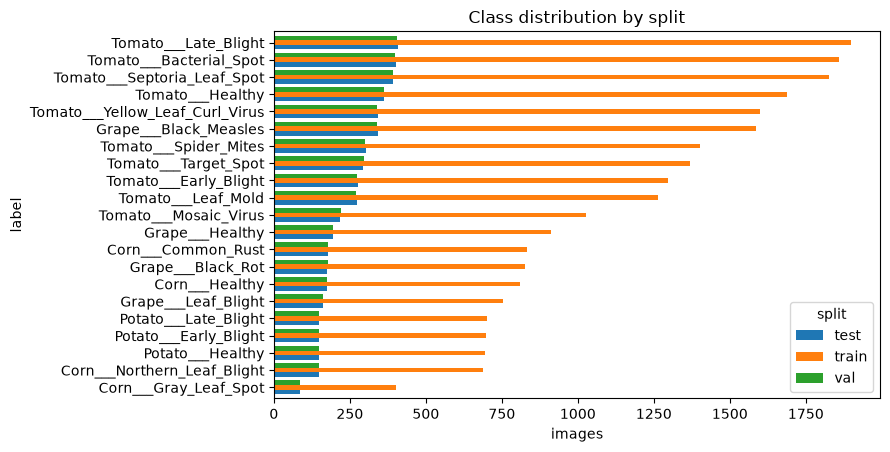

Imbalance ratio (max/min per-class train count): 4.7x


In [11]:
counts = df.groupby(['label', 'split']).size().unstack(fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]

ax = counts.plot.barh(figsize=(9, max(4, len(counts) * 0.22)), width=0.8)
ax.set_xlabel('images')
ax.set_title('Class distribution by split')
plt.tight_layout()
plt.show()

if 'train' in counts.columns:
    ratio = counts['train'].max() / counts['train'].min()
    print(f"Imbalance ratio (max/min per-class train count): {ratio:.1f}x")
else:
    ratio = counts.max(axis=1).max() / counts.max(axis=1).min()
    print(f"Imbalance ratio (overall max/min per-class): {ratio:.1f}x")

## 5. Leakage check (no group crosses splits)

In [12]:
leaks = df.groupby('group')['split'].nunique()
assert (leaks == 1).all(), f"{int((leaks > 1).sum())} groups cross splits"
print(f"{len(leaks)} groups, none cross splits ✓")
print(f"Dedup effect: {prov['n_images']} -> {len(df)} images ({prov['n_images'] - len(df)} merged)")

34481 groups, none cross splits ✓
Dedup effect: 40223 -> 34481 images (5742 merged)


## 6. Sample images per class

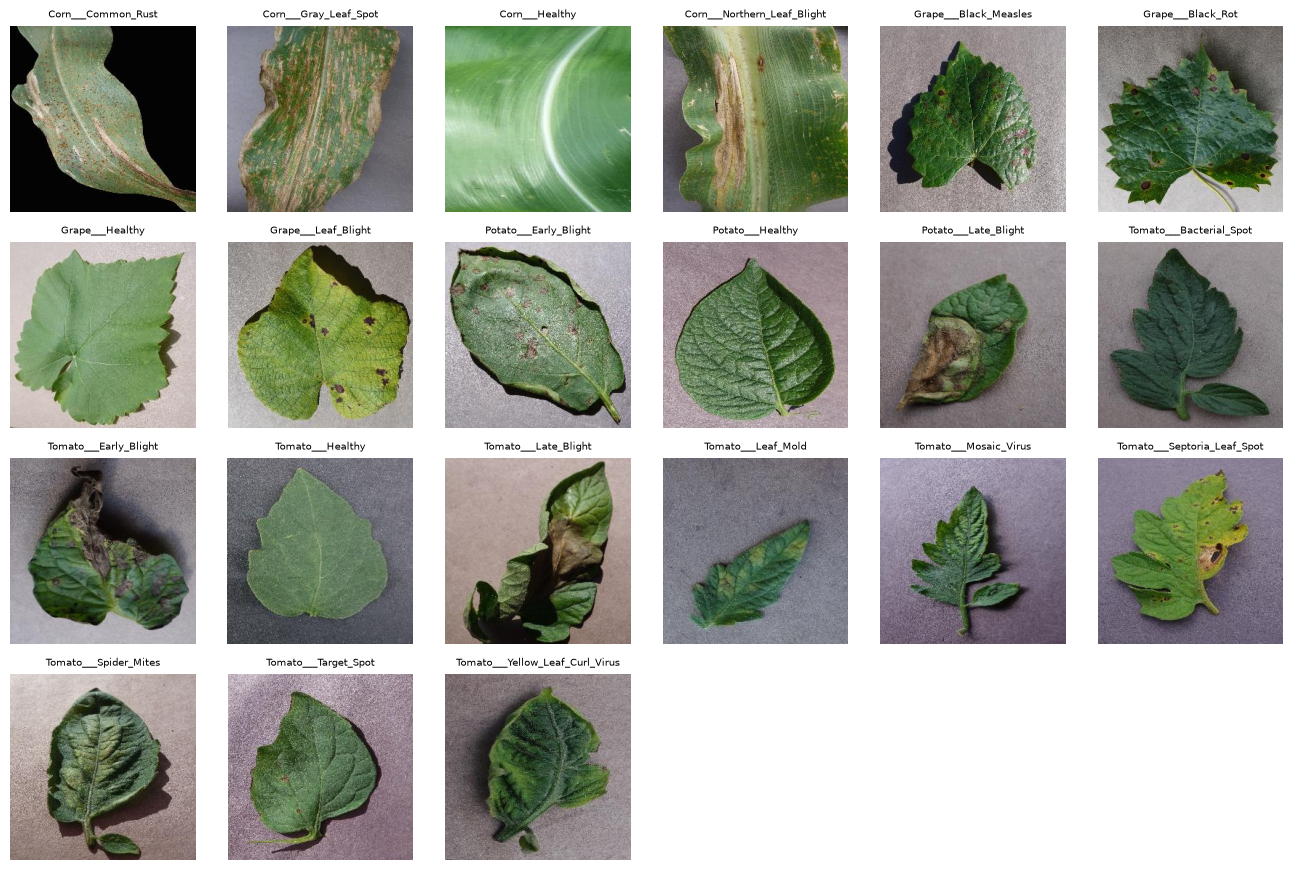

In [13]:
import numpy as np
from PIL import Image
one_per_class = df[df['split'] == 'train'].groupby('label').first().reset_index()
n = len(one_per_class)
cols = 6
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.2))
for ax, (_, r) in zip(axes.flat, one_per_class.iterrows()):
    with Image.open(r['path']) as img:
        ax.imshow(img.convert('RGB'))
    ax.set_title(r['label'], fontsize=7)
    ax.axis('off')
for ax in axes.flat[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()